<a href="https://colab.research.google.com/github/sharaf-omar/CVRPTW/blob/main/CVRPTW_D1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Problem Presentation and Context

## 1.1 The problem addressed

**Topic.** CesiCDP needs to organise **delivery routes**. Trucks leave a depot, deliver a set of customers and then return to the depot. The goal is to **minimise the total duration of the routes**, taking into account the expected traffic in each time slot.

Every day, three decisions must be made:

- **who delivers whom**: assign the customers to the $K$ trucks, which all have the same capacity $Q$, without exceeding that capacity;
- **in which order** each truck visits its customers;
- **at what time** each customer is served: each customer $i$ has a delivery time window $[a_i, b_i]$. If the truck arrives before $a_i$, it waits on site; delivering after $b_i$ is forbidden.

In operations research, this problem is called the **Capacitated Vehicle Routing Problem with Time Windows** (*CVRPTW*). It is the **advanced level (A)** chosen by our team. Without time windows, we get the base case, the *CVRP* (level B).

**Application domain.** The problem belongs to **freight transport logistics**: parcel delivery, store replenishment, postal rounds, waste collection. It is studied with the tools of **combinatorial optimisation**: we look for the best plan among a finite, but huge, number of possible plans.

**Key challenges.**

1. **Combinatorial explosion**: the number of possible plans grows extremely fast with the number of customers. Testing them all is impossible.
2. **Two linked decisions**: assigning customers to trucks and ordering the visits depend on each other and cannot be decided separately.
3. **Time windows**: a single delay early in a route shifts every following delivery and can make the plan infeasible. Arriving too early wastes time waiting.
4. **Size**: the method must handle instances with **several thousand customers** in a reasonable time.
5. **Traffic**: the duration of a trip changes with the time of day.

## 1.2 Context

**Societal context.** Since the 1990s, reducing greenhouse gas emissions has become a global priority. The Kyoto Protocol, signed in 1997, only came into force in 2005. France has since set more ambitious targets for 2050. Since public authorities cannot force companies and individuals to change their habits, they focus on changing practices, especially in transport. Road freight plays a major role in this: fewer kilometres driven and better-filled trucks mean less fuel burned, fewer emissions and less congestion in cities.

**Industrial context.** **ADEME** (the French Agency for Ecological Transition) has issued a call for expressions of interest to support demonstrators of new mobility solutions for people and goods. **CesiCDP**, already active in smart multimodal mobility, is responding with a team of four and has chosen to focus on delivery route management. For a carrier, the stakes are also economic: every minute of driving saved reduces fuel costs, driver working time and vehicle wear.

**Scientific context.** The vehicle routing problem is one of the most studied problems in operations research. Reference mathematical models exist, as well as public benchmark instances with their best known solutions, which makes it possible to measure the quality of a method objectively.

## 1.3 Project objectives

- **For CesiCDP**: submit a solid proposal to ADEME, backed by a route planning tool, in order to obtain funding.
- **For the problem**: compute routes that serve each customer exactly once, respect truck capacity and time windows, and minimise the total duration.
- **For the team**:
  - formally model the problem and study its complexity;
  - design a metaheuristic in Python able to handle several thousand customers;
  - obtain solutions within **7 to 10%** of the best known solutions on reference instances;
  - evaluate the method on at least **20 varied instances**, including an analysis of the effect of time windows.

## 1.4 Concrete examples and use cases

| Use case | Depot | Customers | Capacity | Time window |
|---|---|---|---|---|
| Urban parcel delivery | sorting hub | individuals and shops | van volume | slot promised to the customer |
| Store replenishment | regional warehouse | supermarkets | pallets per truck | store receiving hours |
| Home grocery delivery | warehouse | households | crates per vehicle | slot chosen when ordering |
| Waste collection | treatment centre | collection points | bin volume | authorised collection hours |

**Example.** One morning, CesiCDP must deliver **10 customers** with **3 trucks** of **12 pallets** each, from a depot open from 8:00 to 13:00. The customers order 33 pallets in total, so all three trucks are needed. Each customer imposes a delivery window, for example 8:00–8:30 for a store that receives goods before opening, or 9:00–10:30 for another one. The customers must be split between the trucks and the visiting order must be fixed. A truck that reaches a customer at 8:47 when the window opens at 9:00 waits 13 minutes; if two customers of the same route are swapped, the truck may arrive after a window has closed and the plan is no longer valid. Even on this small case, the choices quickly become complex, which is why an optimisation method is needed.

The figure below shows one feasible plan for this example: the routes on the map, then the timeline of truck 3, which waits 13 minutes before customer 9.

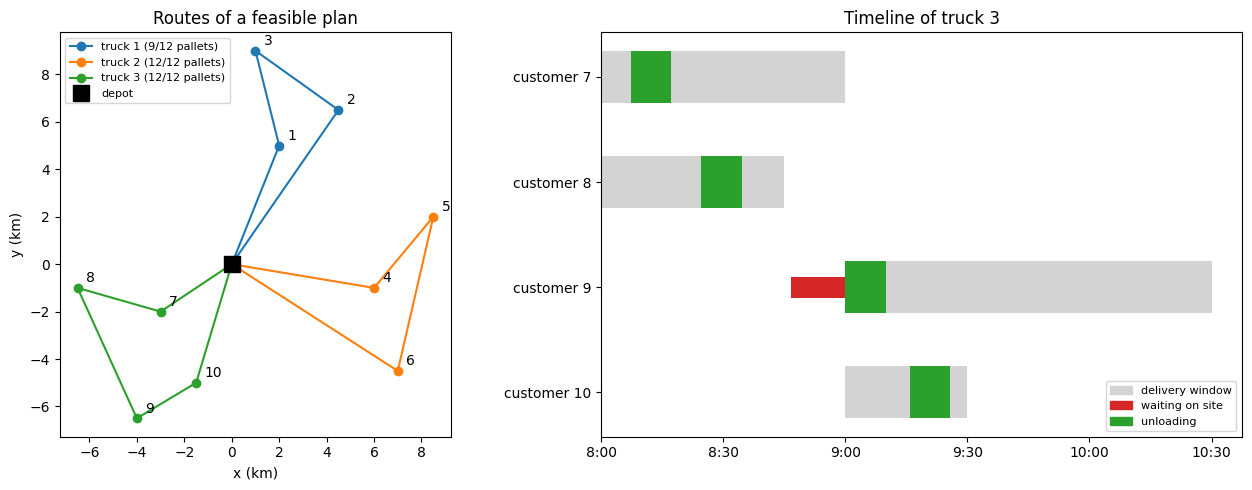

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

# Depot (0) and 10 customers: coordinates in km, demand in pallets, window in minutes after 8:00
coords = np.array([[0, 0], [2, 5], [4.5, 6.5], [1, 9], [6, -1], [8.5, 2], [7, -4.5],
                   [-3, -2], [-6.5, -1], [-4, -6.5], [-1.5, -5]])
demand = [0, 3, 4, 2, 5, 3, 4, 2, 3, 4, 3]
window = {7: (0, 60), 8: (0, 45), 9: (60, 150), 10: (60, 90)}
routes = [[1, 3, 2], [4, 5, 6], [7, 8, 9, 10]]
colors = ["tab:blue", "tab:orange", "tab:green"]
SPEED, SERVICE = 0.5, 10  # 30 km/h = 0.5 km/min, 10 min unloading

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.3]})

# Left: routes on the map
for k, route in enumerate(routes):
    path = coords[[0, *route, 0]]
    load = sum(demand[c] for c in route)
    ax1.plot(path[:, 0], path[:, 1], "-o", color=colors[k], label=f"truck {k + 1} ({load}/12 pallets)")
ax1.plot(0, 0, "ks", ms=12, label="depot")
for i in range(1, 11):
    ax1.annotate(str(i), coords[i], xytext=(6, 4), textcoords="offset points")
ax1.set(title="Routes of a feasible plan", xlabel="x (km)", ylabel="y (km)", aspect="equal")
ax1.legend(loc="upper left", fontsize=8)

# Right: timeline of truck 3 (arrive, wait if early, unload)
clock, prev = 0.0, 0
for row, c in enumerate(routes[2]):
    arrival = clock + np.linalg.norm(coords[c] - coords[prev]) / SPEED
    start = max(arrival, window[c][0])
    a, b = window[c]
    ax2.barh(row, b - a, left=a, color="lightgray", height=0.5)
    if start > arrival:
        ax2.barh(row, start - arrival, left=arrival, color="tab:red", height=0.2)
    ax2.barh(row, SERVICE, left=start, color="tab:green", height=0.5)
    clock, prev = start + SERVICE, c
ax2.set_yticks(range(4), [f"customer {c}" for c in routes[2]])
ax2.set_xticks(range(0, 151, 30), ["8:00", "8:30", "9:00", "9:30", "10:00", "10:30"])
ax2.invert_yaxis()
ax2.set(title="Timeline of truck 3")
ax2.legend(handles=[Patch(color=c, label=l) for c, l in [("lightgray", "delivery window"), ("tab:red", "waiting on site"), ("tab:green", "unloading")]],
           loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

# Part 4 — Theoretical Study of the Problem

**Problem studied:** the Capacitated Vehicle Routing Problem with Time Windows (CVRPTW).

## 4.0 Introduction: what this part requires

The goal of this part is to carry out the theoretical study of the problem. We are asked to:

1. **Identify the complexity class** of the problem (P, NP-complete, NP-hard, ...);
2. **Justify** this classification with
   - a **complexity proof** (reduction to a known problem),
   - **scientific references** (research papers and books);
3. **Explain the implications** of this complexity for potential solving methods, without detailing the methods yet.

**Our approach.** The CVRPTW is built by adding constraints on top of simpler routing problems. We therefore follow a *chain of generalisation*:

$$\text{HC} \;\le_p\; \text{TSP} \;\le_p\; \text{VRP (CVRP)} \;\le_p\; \text{CVRPTW}.$$

- The full scientific approach (membership in NP, reduction, correctness, complexity) is carried out **in detail for the TSP only**, starting from the Hamiltonian Cycle problem, which is known to be NP-complete (Karp, 1972).
- We then pass to the **decision version of the VRP**, and finally to the **CVRPTW**, by using the constraints that are added at each step (vehicles and capacity, then time windows). Each new problem **contains the previous one as a special case**, so it is at least as hard.

## 4.1 The method: how to prove that a problem $\Pi$ is NP-complete

The recipe is always the same six steps.

1. **$\Pi \in NP$.** Describe a certificate (a proposed solution), describe the verification algorithm, and show that both are polynomial.
2. **Choose a known NP-complete problem $\Pi_0$** (similar to $\Pi$: cycles, routes, ...). The direction matters: we reduce $\Pi_0 \le_p \Pi$, the *known* problem to the *new* one.
3. **Describe the transformation $f$**: from any instance $I_0$ of $\Pi_0$, build an instance $f(I_0)$ of $\Pi$.
4. **Show that $f$ runs in polynomial time** (hence the output has polynomial size).
5. **Show the equivalence** $I_0$ is a "yes"-instance $\iff f(I_0)$ is a "yes"-instance. Both directions are needed ("yes" $\to$ "yes" and "no" $\to$ "no", the latter usually through the contrapositive).
6. **Conclude:** $\Pi_0 \le_p \Pi$ so $\Pi$ is NP-hard; with step 1, $\Pi$ is NP-complete.

**Definitions used.**

- A *decision problem* has a yes/no answer for every instance. Optimisation problems ("find the shortest tour") become decision problems by adding a bound $k$ ("is there a tour of length $\le k$?").
- **NP**: decision problems whose "yes"-instances have a certificate of polynomial size that can be verified in polynomial time.
- $A \le_p B$: there is a polynomial-time algorithm $f$ such that $I$ is a "yes"-instance of $A$ $\iff$ $f(I)$ is a "yes"-instance of $B$. Meaning: $B$ is at least as hard as $A$.
- **NP-hard**: every problem of NP reduces to it. **NP-complete**: NP-hard and in NP.

**Typical mistakes to avoid:** reducing in the wrong direction; forgetting membership in NP; proving only one implication; a transformation that is not polynomial; confusing path/cycle, "at least once"/"exactly once", $|V|$ / $|V|-1$.

## 4.2 The Travelling Salesman Problem is NP-complete

### 4.2.1 Decision version of the TSP

- **Data:** a complete weighted graph $G=(V,E)$ with positive integer weights, and an integer $K$.
- **Question:** is there a closed route that passes **at least once** through every vertex, with total weight $\le K$?

Notation: $n=|V|$; $\overline{G}$ is the complement of $G$ (same vertices, an edge exists in $\overline{G}$ iff it does not exist in $G$).

The known problem used for the reduction is **Hamiltonian Cycle (HC)**: given a graph $G$.

### 4.2.2 Part 1: TSP is in NP

Suppose we are given a proposed solution: a sequence of vertices $(w_0, w_1, \dots, w_m = w_0)$. It suffices to check three things:

1. **It is a closed route.** Look at each pair of consecutive vertices and check that they are linked (always true here, since the graph is complete) and that the sequence returns to its starting vertex. This costs $O(m)$.
2. **Every vertex is visited at least once.** Traverse the sequence and tick the vertices seen in a `visited` array. This costs $O(m)$.
3. **The total cost is $\le K$.** Add the weights of the edges used and compare with $K$. This costs $O(m)$.

**Assumption on data access.** We assume that reading the weight of an edge costs $O(1)$ (adjacency matrix). With adjacency lists, one edge test would cost $O(n)$ and the total would be $O(n^2)$, which is still polynomial. The conclusion does not change.

**The certificate has polynomial size.** Since the route may pass several times through the same vertex, we must make sure that a "yes"-instance always has a *short* certificate. Take any valid route and let $x_1,\dots,x_n$ be the vertices in the order of their first visit. Replace the part of the route between $x_i$ and $x_{i+1}$ (and the final part back to $x_1$) by a shortest path between these two vertices. The weight cannot increase, and each shortest path has at most $n-1$ edges. Hence there is always a valid route with at most $n(n-1)$ edges, so the certificate has polynomial size.

**Conclusion:** everything is polynomial (even linear in the length of the route), therefore $\text{TSP} \in NP$. $\square$

### 4.2.3 Part 2: TSP is NP-hard

We want to show $\text{HC} \le_p \text{TSP}$: we transform an instance of HC into an instance of TSP **while keeping the same answer** (yes $\to$ yes, no $\to$ no).

**The transformation.** Start from an arbitrary graph $G=(V,E)$ (not necessarily complete). TSP needs a complete graph, so:

- the edges that exist in $G$ receive weight **1** (they are "good" edges);
- the edges that do not exist in $G$ (the edges of the complement $\overline{G}$) are **added with weight 2** (they are "penalised" edges);
- we choose the bound $K = |V|$ (the number of vertices).

Formally, $G' = (V, E \cup \overline{E})$ with
$$w(x,y)=\begin{cases}1 & \text{if } \{x,y\}\in E,\\ 2 & \text{if } \{x,y\}\in \overline{E},\end{cases}\qquad K=|V|.$$

The following example shows $G$ (5 vertices) and the TSP instance built from it. Solid blue edges have weight 1 (edges of $G$), dashed red edges have weight 2 (added edges).

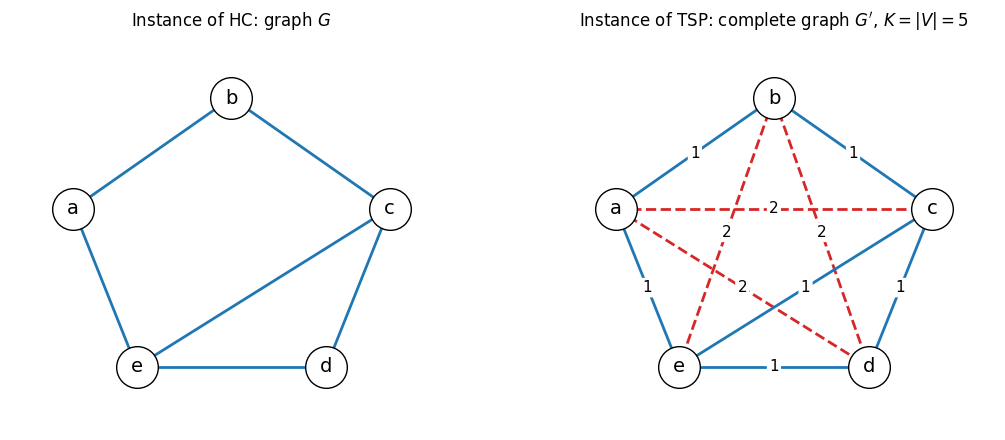

In [ ]:
import matplotlib.pyplot as plt
import itertools

pos = {'a': (0.0, 1.0), 'b': (1.0, 1.7), 'c': (2.0, 1.0), 'd': (1.6, 0.0), 'e': (0.4, 0.0)}
E = {frozenset(p) for p in [('a','b'), ('b','c'), ('c','d'), ('d','e'), ('a','e'), ('c','e')]}
V = list(pos)

def draw_nodes(ax):
    for v, (x, y) in pos.items():
        ax.scatter([x], [y], s=900, facecolor='white', edgecolor='black', zorder=3)
        ax.text(x, y, v, ha='center', va='center', fontsize=14, zorder=4)
    ax.set_aspect('equal'); ax.axis('off'); ax.set_xlim(-0.4, 2.4); ax.set_ylim(-0.4, 2.1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left: the original graph G
ax = axes[0]
for e in E:
    u, v = tuple(e)
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color='tab:blue', lw=2, zorder=1)
draw_nodes(ax)
ax.set_title('Instance of HC: graph $G$')

# Right: the complete TSP graph G'
ax = axes[1]
for u, v in itertools.combinations(V, 2):
    inG = frozenset((u, v)) in E
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]],
            color='tab:blue' if inG else 'tab:red', lw=2, ls='-' if inG else '--', zorder=1)
    mx, my = (pos[u][0] + pos[v][0]) / 2, (pos[u][1] + pos[v][1]) / 2
    ax.text(mx, my, '1' if inG else '2', fontsize=11, ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'), zorder=2)
draw_nodes(ax)
ax.set_title("Instance of TSP: complete graph $G'$, $K=|V|=5$")
plt.tight_layout(); plt.show()

**Polynomial time.** One weight is computed for each of the $n(n-1)/2$ pairs of vertices, so the transformation runs in $O(|V|^2)$, which is polynomial.

**Correctness.** We prove: $G$ has a Hamiltonian cycle $\iff$ the TSP instance answers **yes**.

#### What does "the TSP answers yes" mean?

The decision version of the TSP is a yes/no question: *is there a route visiting every vertex with total cost $\le K$?*

- **yes**: such a route exists;
- **no**: no route respects the budget $K$.

In our construction $K=n$, so "the TSP answers yes" means: *there exists a route visiting all vertices of total cost $\le n$*. A reduction must preserve the answer, so we must prove an **equivalence** between "$G$ has a Hamiltonian cycle" and "the TSP instance answers yes". This is exactly what the two directions below do.

**Direction 1 ($\Rightarrow$): if $G$ has a Hamiltonian cycle, then the TSP answers yes.**
A Hamiltonian cycle uses exactly $n$ edges, all of them in $G$, hence all of weight 1. Its total cost is $n \le K=n$. The TSP therefore finds a valid route: it answers **yes**.

**Direction 2 ($\Leftarrow$): if the TSP answers yes, then $G$ has a Hamiltonian cycle.**
Suppose there is a closed route $R$ visiting all vertices with cost $\le n$, and let $m$ be its number of edges.

- To visit $n$ vertices and come back to the start, $R$ needs at least $n$ edges: $m\ge n$.
- Every edge costs at least 1, so $\text{cost}(R)\ge m\ge n$.
- Since $\text{cost}(R)\le n$, we get $m=n$ **and** every edge has weight exactly 1.

Then $R$ has exactly $n$ edges and visits $n$ different vertices, so it visits **each vertex exactly once**. All its edges have weight 1, so they are edges of $G$ (no added edge was used). Hence $R$ is a Hamiltonian cycle of $G$.

**Why weight 2?** The added edges are "penalised": if the route used even **one** of them, its cost would exceed $n$ and the TSP would answer **no**. So the TSP answers yes only if we can make the tour without leaving the edges of $G$.

**Careful about the bound:** a Hamiltonian cycle has as many edges as vertices, so $K=|V|$ (not $|V|-1$, which would be the case for a path).

**Conclusion.** $\text{HC}\le_p\text{TSP}$, so TSP is NP-hard (HC is NP-complete). Together with Part 1, **TSP is NP-complete**. 

## 4.3 The VRP (CVRP) is NP-hard

### Decision version of the CVRP

- **Data:** a complete weighted graph with a special vertex, the **depot** $d$; customers $V\setminus\{d\}$ with demands $q_i$; $m$ vehicles of capacity $Q$; a bound $k$.
- **Question:** are there at most $m$ routes, each starting and ending at the depot, such that every customer is served by exactly one route, the total demand of each route is $\le Q$, and the total weight of all routes is $\le k$?

### In NP

The certificate is the list of routes. We check in polynomial time that each route starts and ends at the depot, that every customer appears exactly once overall, that each route respects the capacity $Q$, that there are at most $m$ routes, and that the total weight is $\le k$.

### NP-hardness: $\text{TSP}\le_p\text{VRP}$

The VRP is a TSP to which we add **vehicles** and a **capacity**. Given a TSP instance $(G,k)$:

- choose any vertex of $G$ as the **depot** $d$; all other vertices become **customers** with demand $q_i=1$;
- use **one single vehicle** ($m=1$) with capacity $Q \ge$ number of customers, e.g. $Q=|V|-1$, so the capacity **never constrains** the solution;
- keep the same graph and the same bound $k$.

**Polynomial time:** the graph is copied and $O(|V|)$ numbers are added.

**Equivalence.** With one vehicle and a non-binding capacity, a feasible VRP solution is a single closed route through the depot and all the customers, i.e. a TSP tour of the same weight; conversely, a TSP tour starting at $d$ is a feasible VRP solution.

**Remark ("at least once" vs "exactly once").** The TSP allows several passages through a vertex, whereas the VRP serves each customer exactly once. This is harmless for the instances produced by the reduction from HC: their weights (1 and 2) satisfy the **triangle inequality**, so a route that revisits a vertex can always be shortcut without increasing its weight.

**Conclusion.** $\text{TSP}\le_p\text{VRP}$ and $\text{VRP}\in NP$, so the VRP (CVRP) is NP-complete (in particular NP-hard).

## 4.4 The CVRPTW is NP-hard

### Decision version of the CVRPTW

It is the decision CVRP above, with in addition, for each customer $i$:

- a **time window** $[e_i, l_i]$ during which the service must start (arriving early means waiting, arriving late is forbidden);
- a **service time** $s_i$;
- travel times $t_{ij}$ (here equal to the edge weights).

### In NP

The certificate is the list of routes. In addition to the CVRP checks, we compute along each route the arrival times (cumulating travel times, waiting times and service times) and check that every service starts inside its window. All of this is polynomial.

### NP-hardness: $\text{CVRP}\le_p\text{CVRPTW}$

The CVRPTW is a CVRP to which we add **time windows**. Given a CVRP instance:

- give each customer a **very wide window** $[0, M]$, with $M$ large enough that nobody can ever be late (for instance $M$ = the sum of all edge weights, which is an upper bound on the duration of any route of weight $\le k$);
- set all **service times to 0**;
- keep everything else identical (graph, demands, $m$, $Q$, $k$).

**Polynomial time:** we only add one interval and one zero per customer, plus the computation of $M$ in $O(|V|^2)$.

**Equivalence.** With these windows, the time constraints are **never binding**: no arrival can fall outside $[0,M]$ and no waiting is needed. The feasible solutions of the CVRPTW instance are exactly the feasible solutions of the CVRP instance, with the same cost. Hence yes-instances map to yes-instances and no-instances to no-instances.

### Conclusion of the chain

$$\text{TSP}\;\le_p\;\text{VRP}\;\le_p\;\text{CVRPTW}.$$

Each added constraint (vehicles and capacity, then time windows) **generalises** the previous problem: by making it non-binding, we recover the previous problem. Therefore the CVRPTW is at least as hard as the TSP: it is **NP-hard**. Its decision version belongs to NP (capacities, windows and cost are verified in polynomial time), hence it is **NP-complete**.

Time windows even make the problem harder in practice: Savelsbergh (1985) showed that, for the routing problem with time windows, merely deciding whether a **feasible** solution exists is already NP-complete.

## 4.5 Summary of the classification

| Problem | Reduced from | Key idea of the construction | Result |
|---|---|---|---|
| TSP | Hamiltonian Cycle | complete the graph; weight 1 for edges, 2 for non-edges; $K=|V|$ | NP-complete |
| VRP (CVRP) | TSP | 1 vehicle, capacity large enough, same $k$ | NP-hard (decision version NP-complete) |
| CVRPTW | CVRP | windows $[0,M]$ with $M$ large, service times 0 | NP-hard (decision version NP-complete) |

**Complexity class of our problem: the CVRPTW is NP-hard** (its decision version is NP-complete).

## 4.6 Implications for the solving methods

We only discuss here what the complexity result implies; the methods themselves will be detailed in the next parts.

1. **No polynomial exact algorithm is expected.** Since the CVRPTW is NP-hard, no algorithm solving it optimally in polynomial time is expected to exist, unless $P=NP$.
2. **Exact methods are limited in size.** Exact methods guarantee optimality, but their running time grows exponentially with the number of customers. They are practical only for small to medium-sized instances.
3. **For large instances we must give up the optimality guarantee.** We turn to approximate methods (heuristics and metaheuristics), which produce good solutions in reasonable time but without a guarantee of optimality.
4. **The added constraints make the search harder.** The capacity and time-window constraints make even *finding a feasible solution* difficult, so the chosen method will have to handle feasibility explicitly.
5. **Solution quality must be assessed empirically.** Without an optimality guarantee, solutions are evaluated by comparison with bounds or best-known solutions on benchmark instances (Solomon instances, VRPLIB), for example through the gap to the best known value.

## 4.7 References

1. S. A. Cook. *The complexity of theorem-proving procedures.* Proceedings of the 3rd Annual ACM Symposium on Theory of Computing (STOC), 1971, pp. 151–158. — NP-completeness of SAT.
2. R. M. Karp. *Reducibility among combinatorial problems.* In R. E. Miller and J. W. Thatcher (eds.), *Complexity of Computer Computations*, Plenum Press, 1972, pp. 85–103. — NP-completeness of Hamiltonian Cycle.
3. M. R. Garey and D. S. Johnson. *Computers and Intractability: A Guide to the Theory of NP-Completeness.* W. H. Freeman, 1979. — Framework of NP-completeness; TSP and Hamiltonian Cycle.
4. G. B. Dantzig and J. H. Ramser. *The truck dispatching problem.* Management Science, 6(1), 1959, pp. 80–91. — Origin of the VRP.
5. J. K. Lenstra and A. H. G. Rinnooy Kan. *Complexity of vehicle routing and scheduling problems.* Networks, 11(2), 1981, pp. 221–227. — NP-hardness of the VRP.
6. M. W. P. Savelsbergh. *Local search in routing problems with time windows.* Annals of Operations Research, 4, 1985, pp. 285–305. — Difficulty of time windows (feasibility is already NP-complete).
7. M. M. Solomon. *Algorithms for the vehicle routing and scheduling problems with time window constraints.* Operations Research, 35(2), 1987, pp. 254–265. — Benchmark instances for the VRPTW.
8. P. Toth and D. Vigo (eds.). *Vehicle Routing: Problems, Methods, and Applications* (2nd ed.). SIAM, 2014. — Reference book on the VRP and its variants.